# Simple Linear Regression – Medical Insurance Dataset

Linear Regression is a supervised machine learning technique used to predict numerical values. In this project, Linear Regression is used to predict medical insurance charges based on customer information such as age, BMI, smoking status, and other features. The model's performance is evaluated using MAE, MSE, RMSE, and R² score.

In [1]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv("insurance.csv")

# Display first five rows
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
# Check dataset size
print("Dataset Shape:", df.shape)

# Check column information
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (1338, 7)
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [3]:
# Input features
X = df.drop("charges", axis=1)

# Target variable
y = df["charges"]

print("Input Features:")
print(X.head())

print("\nTarget Variable (Charges):")
print(y.head())

Input Features:
   age     sex     bmi  children smoker     region
0   19  female  27.900         0    yes  southwest
1   18    male  33.770         1     no  southeast
2   28    male  33.000         3     no  southeast
3   33    male  22.705         0     no  northwest
4   32    male  28.880         0     no  northwest

Target Variable (Charges):
0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64


In [4]:
# Convert categorical data into numerical data
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Converted Input Features:")
print(X.head())

print("\nTotal Features:", X.shape[1])

Converted Input Features:
   age     bmi  children  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0         0           1                 0   
1   18  33.770         1         1           0                 0   
2   28  33.000         3         1           0                 0   
3   33  22.705         0         1           0                 1   
4   32  28.880         0         1           0                 1   

   region_southeast  region_southwest  
0                 0                 1  
1                 1                 0  
2                 1                 0  
3                 0                 0  
4                 0                 0  

Total Features: 8


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 1070
Testing Records: 268


In [7]:
from sklearn.linear_model import LinearRegression

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [8]:
# Predict insurance charges
y_pred = model.predict(X_test)

print("Actual Charges:")
print(y_test.head(10).tolist())

print("\nPredicted Charges:")
print(y_pred[:10])

Actual Charges:
[9095.06825, 5272.1758, 29330.98315, 9301.89355, 33750.2918, 4536.259, 2117.33885, 14210.53595, 3732.6251, 10264.4421]

Predicted Charges:
[ 8969.55027444  7068.74744287 36858.41091155  9454.67850053
 26973.17345656 10864.11316424   170.28084136 16903.45028662
  1092.43093614 11218.34318352]


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Mean Absolute Error (MAE): 4181.19
Mean Squared Error (MSE): 33596915.85
Root Mean Squared Error (RMSE): 5796.28
R2 Score: 0.7836


MAE: Average prediction error.



MSE: Average squared prediction error.



RMSE: Prediction error in the original charges units.



R² Score: Shows how well the model explains the variation in charges. Closer to 1 is generally better.

**ACTUAL VS. PREDICTED GRAPH**

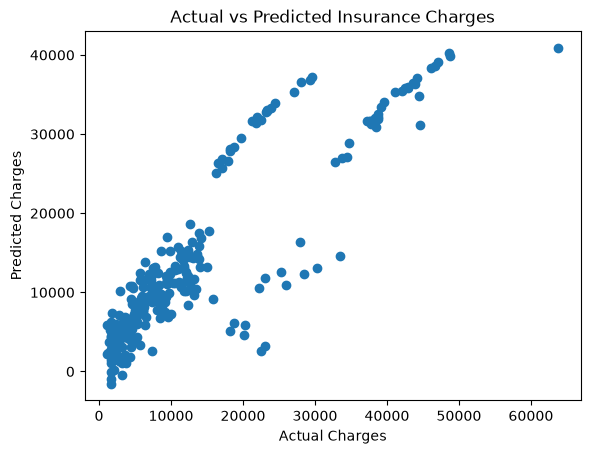

In [10]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Insurance Charges")
plt.show()

In [11]:
print("LINEAR REGRESSION SUMMARY")
print("-------------------------")
print("Algorithm: Linear Regression")
print("Dataset: Medical Insurance")
print("Total Records:", len(df))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Input Features:", X.shape[1])
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

LINEAR REGRESSION SUMMARY
-------------------------
Algorithm: Linear Regression
Dataset: Medical Insurance
Total Records: 1338
Training Records: 1070
Testing Records: 268
Input Features: 8
MAE: 4181.19
MSE: 33596915.85
RMSE: 5796.28
R2 Score: 0.7836
